# 03 - Exploratory Analysis

**Energy Transition & Electric Mobility in Portugal**

Questions explored, in order:

1. How has the renewable share of electricity evolved?
2. What is the seasonal pattern, and does it repeat every year?
3. Which renewable sources are the most volatile?
4. Why did the renewable share drop in spring 2025?
5. Where is electric mobility consumption concentrated?
6. Do renewables push market prices down, and are Portugal/Spain market splits linked to high renewable output?

The notebook only reads the tables written by `02_cleaning.ipynb`, so it can be re-run from top to bottom after every update.

## Setup and data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether the notebook sits in notebooks/ or in the project root
CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

df_ren = pd.read_csv(
    DATA_PROCESSED / "ren_daily_production.csv", parse_dates=["date"]
).sort_values("date")
df_prices = pd.read_csv(
    DATA_PROCESSED / "ren_market_prices_daily.csv", parse_dates=["date"]
)
df_mobility = pd.read_csv(
    DATA_PROCESSED / "eredes_mobility_monthly.csv", parse_dates=["date"]
)

df_ren["year"] = df_ren["date"].dt.year
df_ren["month"] = df_ren["date"].dt.month

MONTH_NAMES = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]
RENEWABLE = ["hydro_mwh", "solar_mwh", "wind_mwh", "biomass_mwh", "wave_mwh"]

# Years with (almost) every day present; partial years are left out of year-to-year comparisons
days_per_year = df_ren.groupby("year").size()
FULL_YEARS = [int(y) for y, n in days_per_year.items() if n >= 360]

SHARE_INPUTS = ["renewable_mwh", "total_production_mwh", "import_mwh"]


def energy_shares(df):
    """Renewable and import shares of a set of days, weighted by energy.

    The share of a period is its renewable energy over its total energy, not the average of the
    daily percentages, so a day with a lot of production counts more than a quiet one.
    """
    renewable = df["renewable_mwh"].sum()
    production = df["total_production_mwh"].sum()
    supply = production + df["import_mwh"].fillna(0).sum()
    return pd.Series(
        {
            "pct_renewable": renewable / production * 100,
            "pct_renewable_incl_imports": renewable / supply * 100,
            "import_share_pct": (supply - production) / supply * 100,
        }
    )


print(
    f"Production: {len(df_ren)} days, {df_ren['date'].min().date()} to {df_ren['date'].max().date()}"
)
print(
    f"Prices: {len(df_prices)} days | Electric mobility: {df_mobility['date'].nunique()} months"
)
print(f"Full years: {FULL_YEARS}")

Production: 1827 days, 2021-10-28 to 2026-10-28
Prices: 1827 days | Electric mobility: 12 months
Full years: [2022, 2023, 2024, 2025]


### Chart style

One style and one colour per source for every chart in the project, so the same colour always means the same thing (the dashboard reuses these).

In [2]:
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#E6E6E6",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "legend.frameon": False,
    }
)

MAIN_COLOR = "#1F5A8A"
ACCENT_COLOR = "#D9822B"
SOURCE_COLORS = {
    "hydro_mwh": "#2C7FB8",
    "wind_mwh": "#41AE76",
    "solar_mwh": "#E6A700",
    "biomass_mwh": "#8C6D31",
    "natural_gas_mwh": "#7F7F7F",
    "other_thermal_mwh": "#B5B5B5",
    "import_mwh": "#8E6BB0",
    "export_mwh": "#C7B5DE",
    "consumption_mwh": "#333333",
}
SOURCE_LABELS = {
    "hydro_mwh": "Hydro",
    "wind_mwh": "Wind",
    "solar_mwh": "Solar",
    "biomass_mwh": "Biomass",
    "wave_mwh": "Wave",
    "natural_gas_mwh": "Natural gas",
    "other_thermal_mwh": "Other thermal",
    "import_mwh": "Imports",
    "export_mwh": "Exports",
    "consumption_mwh": "Consumption",
}


def year_colors(years):
    """Oldest year light, most recent year dark (starts at 0.3 so the oldest line stays visible)."""
    return dict(zip(years, plt.cm.Blues(np.linspace(0.3, 1.0, len(years)))))


def year_label(year):
    return str(year) if year in FULL_YEARS else f"{year} (partial)"

## 1. Overview of the renewable share

The share for a year, a month or any other group of days is weighted by energy: renewable MWh over total MWh in that period, the same definition the dashboard uses. Averaging the daily percentages instead would give a quiet day as much weight as a busy one, which moves the yearly figures by around one point.

In [3]:
yearly = df_ren.groupby("year")[SHARE_INPUTS].apply(energy_shares)
yearly.insert(0, "days", df_ren.groupby("year").size())
yearly.index = [year_label(y) for y in yearly.index]
yearly.round(1)

,days,pct_renewable,pct_renewable_incl_imports,import_share_pct
2021 (partial),65,68.6,59.1,13.9
2022,365,62.3,49.8,20.1
2023,365,77.2,60.4,21.8
2024,366,88.7,69.0,22.2
2025,365,83.8,68.0,18.8
2026 (partial),301,83.8,63.9,23.7


### Renewable share over time

Daily values are noisy, so the chart shows the share over a rolling 7-day window (renewable energy over total energy in those 7 days), with dashed lines at the start of each year. The two lines are the two definitions from the cleaning notebook.

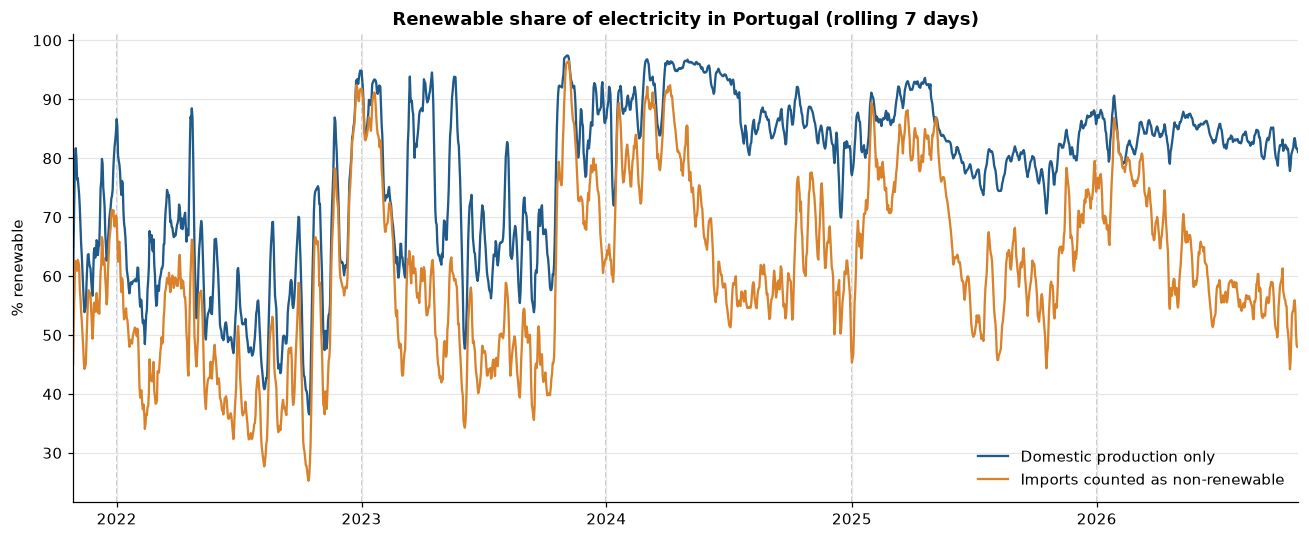

In [4]:
def plot_renewable_share(df, window_days=7):
    sums = (
        df.set_index("date")[SHARE_INPUTS]
        .fillna({"import_mwh": 0})
        .rolling(f"{window_days}D")
        .sum()
    )
    smoothed = pd.DataFrame(
        {
            "pct_renewable": sums["renewable_mwh"] / sums["total_production_mwh"] * 100,
            "pct_renewable_incl_imports": sums["renewable_mwh"]
            / (sums["total_production_mwh"] + sums["import_mwh"])
            * 100,
        }
    )

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(
        smoothed.index,
        smoothed["pct_renewable"],
        color=MAIN_COLOR,
        label="Domestic production only",
    )
    ax.plot(
        smoothed.index,
        smoothed["pct_renewable_incl_imports"],
        color=ACCENT_COLOR,
        label="Imports counted as non-renewable",
    )

    for year in range(df["date"].dt.year.min() + 1, df["date"].dt.year.max() + 1):
        ax.axvline(
            pd.Timestamp(f"{year}-01-01"),
            color="#BDBDBD",
            linestyle="--",
            linewidth=1,
            zorder=0,
        )

    ax.set_xlim(df["date"].min(), df["date"].max())
    ax.set_ylabel("% renewable")
    ax.set_title(
        f"Renewable share of electricity in Portugal (rolling {window_days} days)"
    )
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


plot_renewable_share(df_ren)

## 2. Seasonality

Renewable share by calendar month. Only full years are used: the partial first and last years cover just some months and would pull those months towards a single year.

month
Jan    81.9
Feb    77.7
Mar    83.7
Apr    85.3
May    79.2
Jun    71.6
Jul    69.6
Aug    70.9
Sep    71.9
Oct    76.4
Nov    79.8
Dec    83.7


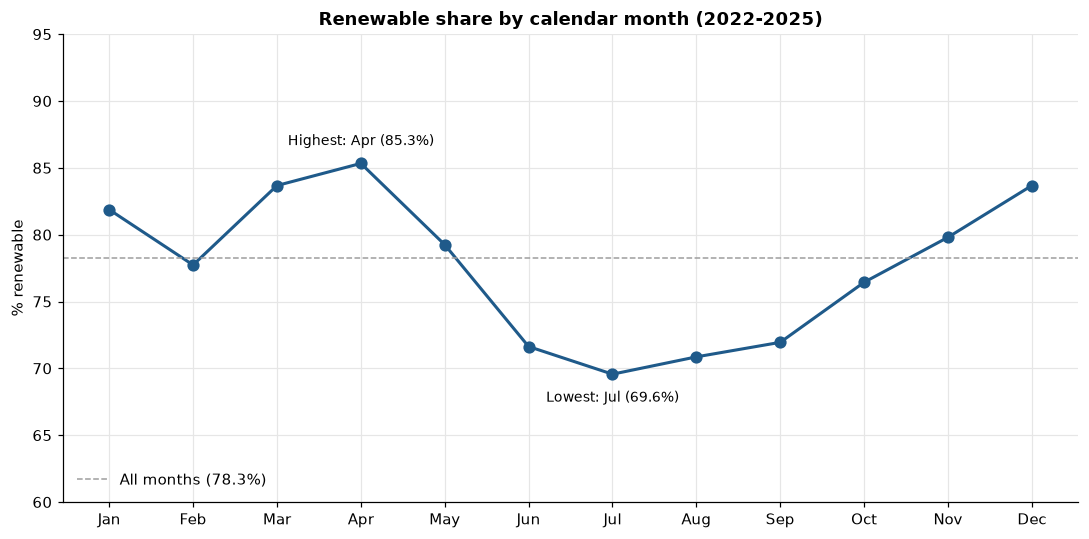

In [ ]:
df_full = df_ren[df_ren["year"].isin(FULL_YEARS)]
monthly_share = df_full.groupby("month")[SHARE_INPUTS].apply(energy_shares)[
    "pct_renewable"
]
print(
    monthly_share.round(1)
    .rename(index=dict(enumerate(MONTH_NAMES, start=1)))
    .to_string()
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    monthly_share.index,
    monthly_share.values,
    marker="o",
    markersize=7,
    linewidth=2,
    color=MAIN_COLOR,
)

overall_share = energy_shares(df_full)["pct_renewable"]
ax.axhline(
    overall_share,
    color="#9E9E9E",
    linestyle="--",
    linewidth=1,
    label=f"All months ({overall_share:.1f}%)",
)

for month, label in [
    (monthly_share.idxmax(), "Highest"),
    (monthly_share.idxmin(), "Lowest"),
]:
    ax.annotate(
        f"{label}: {MONTH_NAMES[month - 1]} ({monthly_share[month]:.1f}%)",
        xy=(month, monthly_share[month]),
        xytext=(0, 12 if label == "Highest" else -18),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTH_NAMES)
ax.set_ylim(
    np.floor(monthly_share.min() / 5) * 5 - 5, np.ceil(monthly_share.max() / 5) * 5 + 5
)
ax.set_ylabel("% renewable")
ax.set_title(f"Renewable share by calendar month ({FULL_YEARS[0]}-{FULL_YEARS[-1]})")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

### Seasonality year by year

One line per year shows whether the seasonal shape repeats or whether some years behave differently. Partial years are included here and marked as such in the legend.

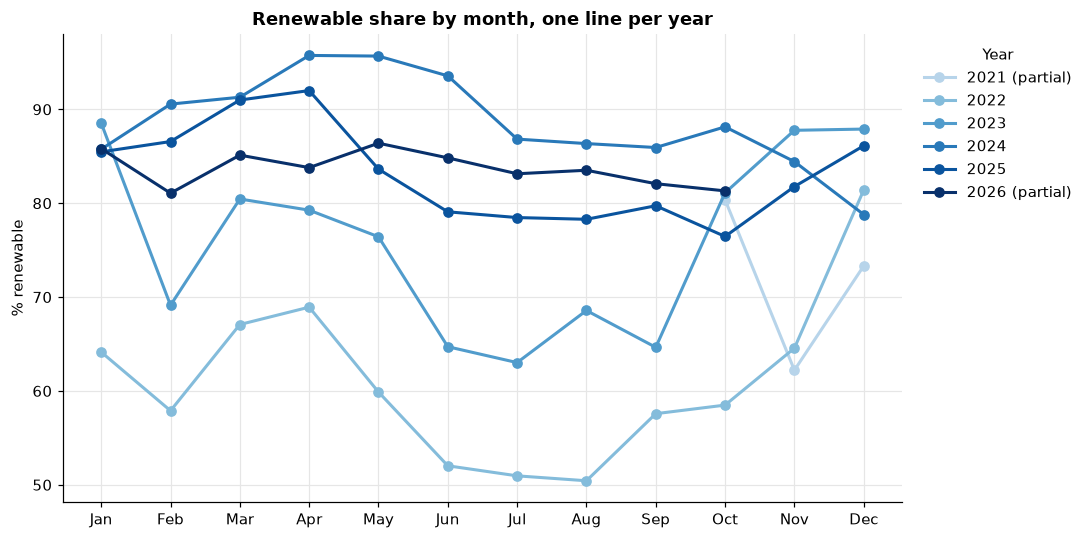

In [6]:
monthly_by_year = (
    df_ren.groupby(["month", "year"])[SHARE_INPUTS]
    .apply(energy_shares)["pct_renewable"]
    .unstack()
)
colors = year_colors(list(monthly_by_year.columns))

fig, ax = plt.subplots(figsize=(10, 5))
for year in monthly_by_year.columns:
    ax.plot(
        monthly_by_year.index,
        monthly_by_year[year],
        marker="o",
        linewidth=2,
        color=colors[year],
        label=year_label(year),
    )

ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTH_NAMES)
ax.set_ylabel("% renewable")
ax.set_title("Renewable share by month, one line per year")
ax.legend(title="Year", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 3. Volatility of renewable sources

The coefficient of variation (standard deviation divided by the mean) compares volatility fairly between sources with very different output levels. Sources that never produce are left out.

Over the whole period the coefficient mixes day-to-day volatility with long-term growth (installed solar capacity has grown a lot), so it is also computed **inside each full year**, where growth matters much less.

Left out (zero on every day): ['Wave']

Coefficient of variation, whole period:
Wind       0.653
Hydro      0.618
Solar      0.586
Biomass    0.125

Coefficient of variation inside each full year:
      Hydro  Solar   Wind  Biomass
year                              
2022  0.813  0.383  0.639    0.088
2023  0.699  0.366  0.668    0.088
2024  0.526  0.414  0.633    0.099
2025  0.471  0.442  0.656    0.080


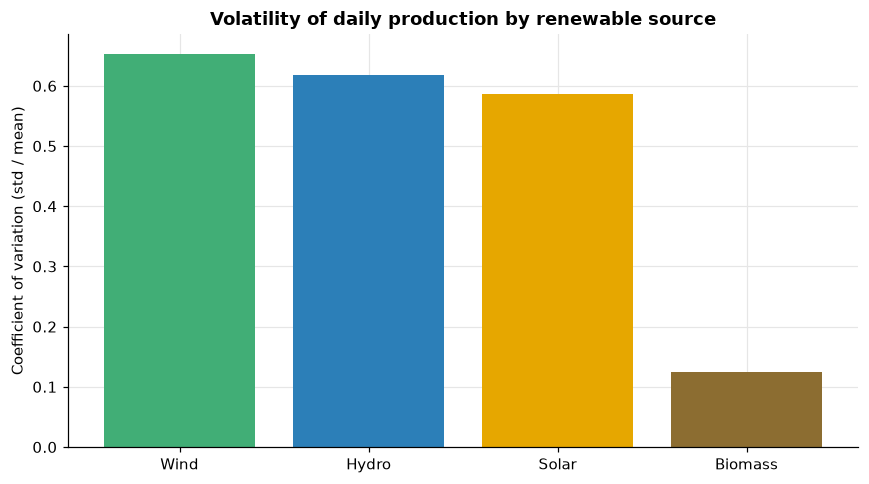

In [7]:
active = [s for s in RENEWABLE if df_ren[s].max() > 0]
print(
    f"Left out (zero on every day): {[SOURCE_LABELS[s] for s in RENEWABLE if s not in active]}"
)

cv_pooled = (df_ren[active].std() / df_ren[active].mean()).sort_values(ascending=False)
cv_by_year = df_full.groupby("year")[active].agg(lambda s: s.std() / s.mean())

print("\nCoefficient of variation, whole period:")
print(cv_pooled.rename(SOURCE_LABELS).round(3).to_string())
print("\nCoefficient of variation inside each full year:")
print(cv_by_year.rename(columns=SOURCE_LABELS).round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(
    [SOURCE_LABELS[s] for s in cv_pooled.index],
    cv_pooled.values,
    color=[SOURCE_COLORS[s] for s in cv_pooled.index],
)
ax.set_ylabel("Coefficient of variation (std / mean)")
ax.set_title("Volatility of daily production by renewable source")
plt.tight_layout()
plt.show()

## 4. Why did the renewable share drop in spring 2025?

Average daily production by month, one line per full year, for the three main renewable sources and for natural gas.

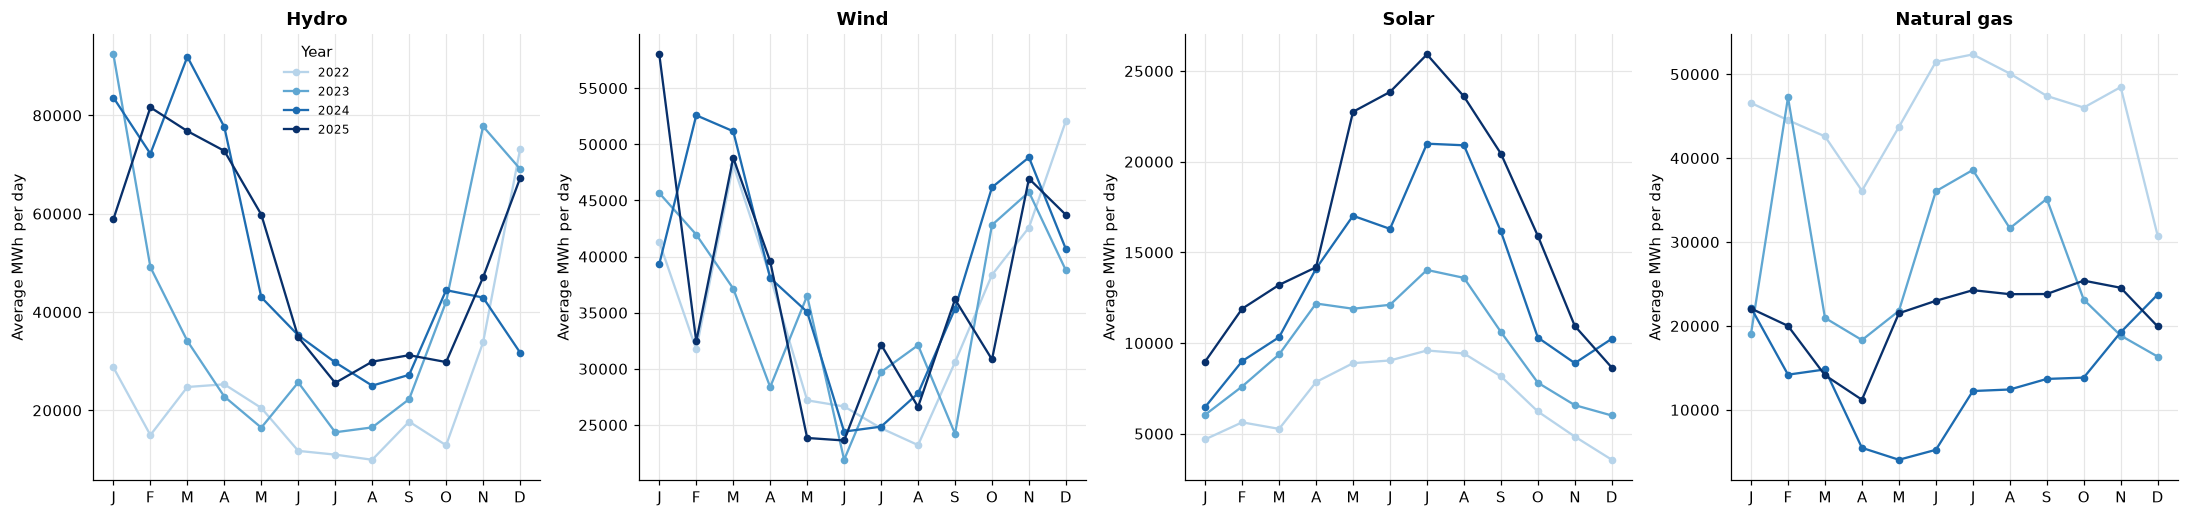

In [8]:
sources_to_plot = ["hydro_mwh", "wind_mwh", "solar_mwh", "natural_gas_mwh"]
colors = year_colors(FULL_YEARS)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharex=True)
for ax, source in zip(axes, sources_to_plot):
    by_year = df_full.groupby(["month", "year"])[source].mean().unstack()
    for year in FULL_YEARS:
        ax.plot(
            by_year.index,
            by_year[year],
            marker="o",
            markersize=4,
            color=colors[year],
            label=str(year),
        )
    ax.set_title(SOURCE_LABELS[source])
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([m[0] for m in MONTH_NAMES])
    ax.set_ylabel("Average MWh per day")
axes[0].legend(title="Year", fontsize=8)
plt.tight_layout()
plt.show()

### April to June, 2024 vs 2025

Comparing the same three months in both years separates the possible causes: less renewable production, more demand, or more fossil production. Imports and exports are included because they are part of the supply.

In [9]:
COMPARE_YEARS = (2024, 2025)
COMPARE_MONTHS = [4, 5, 6]
COMPARE_SOURCES = [
    "hydro_mwh",
    "wind_mwh",
    "solar_mwh",
    "biomass_mwh",
    "natural_gas_mwh",
    "other_thermal_mwh",
    "import_mwh",
    "export_mwh",
    "consumption_mwh",
]

before, after = COMPARE_YEARS
window = df_ren[
    df_ren["month"].isin(COMPARE_MONTHS) & df_ren["year"].isin(COMPARE_YEARS)
]
means = window.groupby("year")[COMPARE_SOURCES + ["renewable_mwh"]].mean()
means["pct_renewable"] = window.groupby("year")[SHARE_INPUTS].apply(energy_shares)[
    "pct_renewable"
]

comparison = means[COMPARE_SOURCES].T
comparison.columns = [f"{before}_mwh_per_day", f"{after}_mwh_per_day"]
comparison["change_mwh_per_day"] = comparison.iloc[:, 1] - comparison.iloc[:, 0]
comparison["change_pct"] = (
    comparison["change_mwh_per_day"] / comparison.iloc[:, 0] * 100
)
comparison.index = [SOURCE_LABELS[s] for s in comparison.index]
print(comparison.round(1))

change = means.loc[after] - means.loc[before]
print(
    f"\nRenewable share: {means.loc[before, 'pct_renewable']:.1f}% -> {means.loc[after, 'pct_renewable']:.1f}% "
    f"({change['pct_renewable']:+.1f} pp)"
)
print(
    f"Change in MWh per day: renewables {change['renewable_mwh']:+,.0f} | "
    f"natural gas {change['natural_gas_mwh']:+,.0f} | imports {change['import_mwh']:+,.0f} | "
    f"consumption {change['consumption_mwh']:+,.0f}"
)

               2024_mwh_per_day  2025_mwh_per_day  change_mwh_per_day  \
Hydro                   51872.5           55876.4              4003.9   
Wind                    32552.4           28954.4             -3598.0   
Solar                   15819.4           20286.5              4467.1   
Biomass                  9240.3            7280.0             -1960.3   
Natural gas              4910.2           18604.2             13694.0   
Other thermal             664.6             610.4               -54.2   
Imports                 37035.1           25040.7            -11994.4   
Exports                  6997.6            8162.5              1164.9   
Consumption            131399.6          133700.8              2301.2   

               change_pct  
Hydro                 7.7  
Wind                -11.1  
Solar                28.2  
Biomass             -21.2  
Natural gas         278.9  
Other thermal        -8.2  
Imports             -32.4  
Exports              16.6  
Consumption      

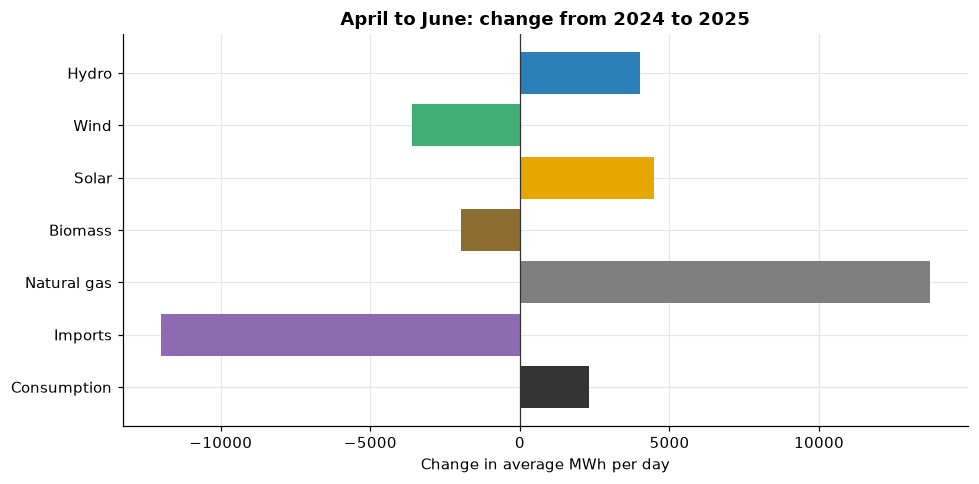

In [10]:
plot_sources = [
    "hydro_mwh",
    "wind_mwh",
    "solar_mwh",
    "biomass_mwh",
    "natural_gas_mwh",
    "import_mwh",
    "consumption_mwh",
]
values = (means.loc[after] - means.loc[before])[plot_sources]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(
    [SOURCE_LABELS[s] for s in plot_sources],
    values.values,
    color=[SOURCE_COLORS[s] for s in plot_sources],
)
ax.axvline(0, color="#333333", linewidth=0.8)
ax.invert_yaxis()
ax.set_xlabel("Change in average MWh per day")
ax.set_title(f"April to June: change from {before} to {after}")
plt.tight_layout()
plt.show()

### Day by day around the blackout

Gas output and imports from March to August 2025 (7-day rolling average), with the same months of 2024 for comparison.

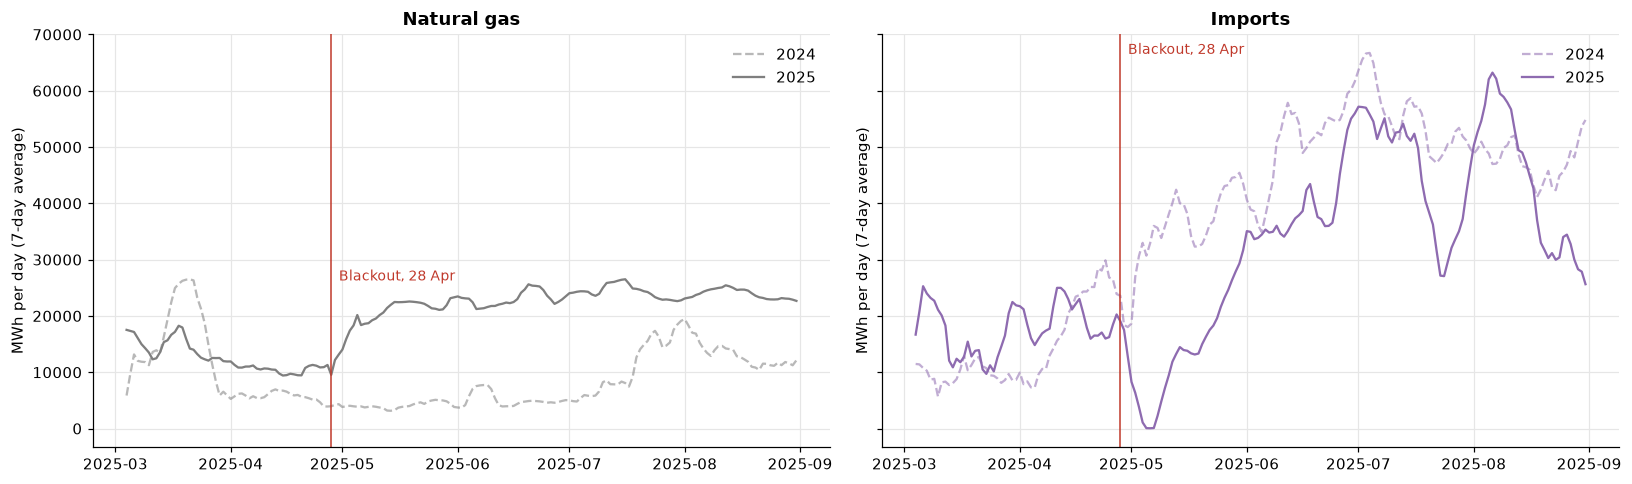

In [ ]:
BLACKOUT = pd.Timestamp("2025-04-28")
daily = df_ren.set_index("date")[["natural_gas_mwh", "import_mwh"]]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, source in zip(axes, ["natural_gas_mwh", "import_mwh"]):
    for year, style in [(2024, "--"), (2025, "-")]:
        part = (
            daily.loc[f"{year}-03-01" : f"{year}-08-31", source]
            .rolling(7, min_periods=4)
            .mean()
        )
        # Plot both years on the same 2025 calendar so the lines overlap
        part.index = part.index.map(lambda d: d.replace(year=2025))
        ax.plot(
            part.index,
            part.values,
            linestyle=style,
            color=SOURCE_COLORS[source],
            alpha=0.55 if year == 2024 else 1.0,
            label=str(year),
        )
    ax.axvline(BLACKOUT, color="#C0392B", linewidth=1)
    ax.annotate(
        "Blackout, 28 Apr",
        xy=(BLACKOUT, ax.get_ylim()[1] * 0.95),
        xytext=(5, 0),
        textcoords="offset points",
        fontsize=9,
        color="#C0392B",
    )
    ax.set_title(SOURCE_LABELS[source])
    ax.set_ylabel("MWh per day (7-day average)")
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### Reading the comparison

Renewable production did not fall between the two springs; it rose slightly, with more hydro and solar making up for less wind and biomass. The share dropped because natural gas output grew strongly while demand barely moved.

The daily data shows when it happened. On 29 April 2025, the day after the Iberian blackout, imports fell to almost zero for nine days and gas output jumped. Imports had mostly recovered by June, at about four fifths of their June 2024 level, but gas stayed far above its 2024 level from May to November. In December it was slightly lower than a year earlier. The extra gas was therefore not only filling in for missing imports.

After the blackout, the Spanish system operator ran its grid in a reinforced mode, keeping more than twenty gas-fired plants available to control voltage ([ENTSO-E report page](https://www.entsoe.eu/publications/blackout/28-april-2025-Iberian-blackout), [Ara](https://en.ara.cat/economy/red-electrica-estimates-the-cost-of-reinforcing-the-electrical-system-since-the-blackout-at-317-million-euros_1_5531132.amp.html)). A lasting rise in Portuguese gas output is consistent with a similarly cautious operation of the Iberian system, but this data alone does not prove the cause.

## 5. Electric mobility by geography

Total electric mobility consumption per municipality and district for the months available in E-REDES (mainland Portugal only), plus the monthly total.

Period: 2025-05 to 2026-04 | total 217,755 MWh
Top 10 municipalities: 41.7% of the mainland total
Lisbon district: 37.1% | Porto district: 15.9%


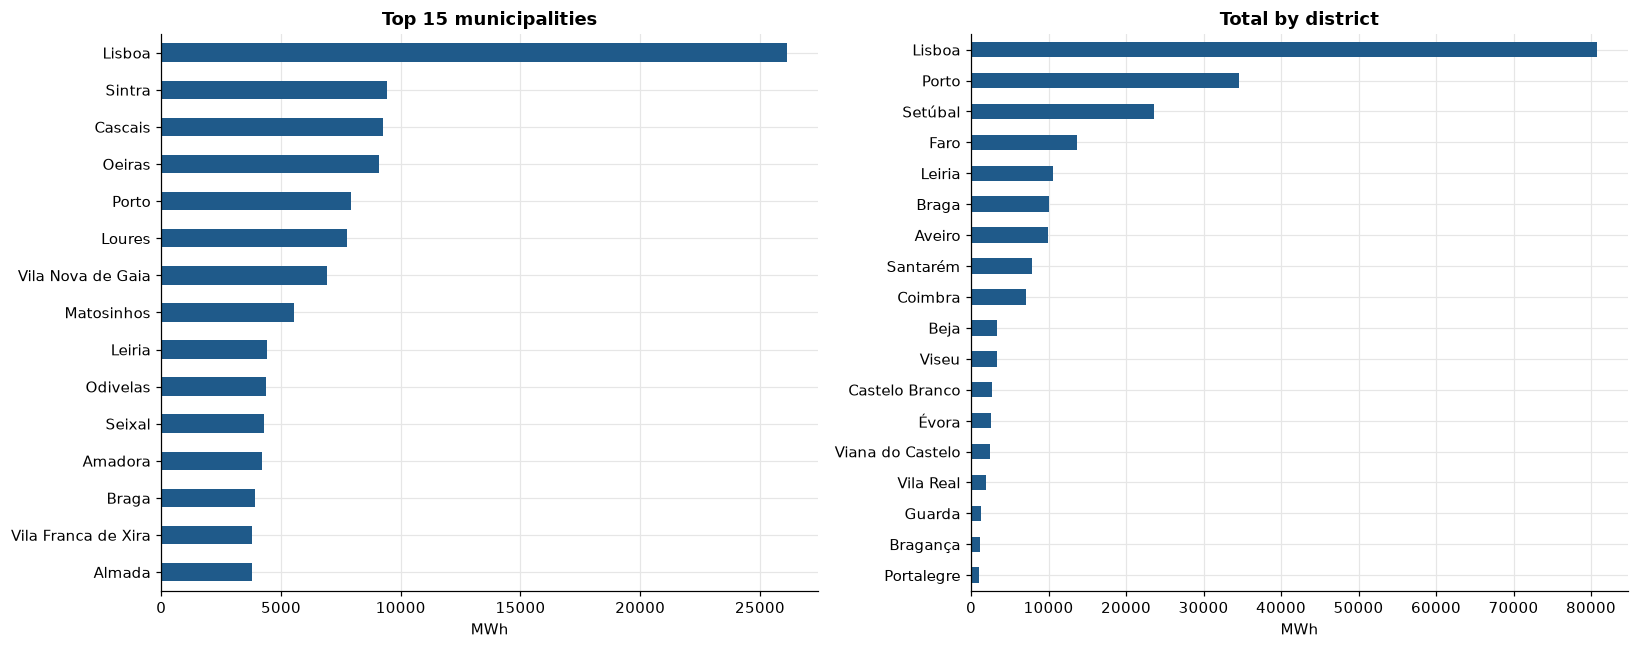

In [12]:
total_mwh = df_mobility["energy_mwh"].sum()
top_municipalities = (
    df_mobility.groupby("municipality")["energy_mwh"].sum().nlargest(15)
)
by_district = df_mobility.groupby("district")["energy_mwh"].sum().sort_values()

print(
    f"Period: {df_mobility['date'].min():%Y-%m} to {df_mobility['date'].max():%Y-%m} | total {total_mwh:,.0f} MWh"
)
print(
    f"Top 10 municipalities: {top_municipalities.head(10).sum() / total_mwh * 100:.1f}% of the mainland total"
)
print(
    f"Lisbon district: {by_district.get('Lisboa', 0) / total_mwh * 100:.1f}% | "
    f"Porto district: {by_district.get('Porto', 0) / total_mwh * 100:.1f}%"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_municipalities.sort_values().plot(kind="barh", ax=axes[0], color=MAIN_COLOR)
axes[0].set_title("Top 15 municipalities")
axes[0].set_xlabel("MWh")
axes[0].set_ylabel("")

by_district.plot(kind="barh", ax=axes[1], color=MAIN_COLOR)
axes[1].set_title("Total by district")
axes[1].set_xlabel("MWh")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

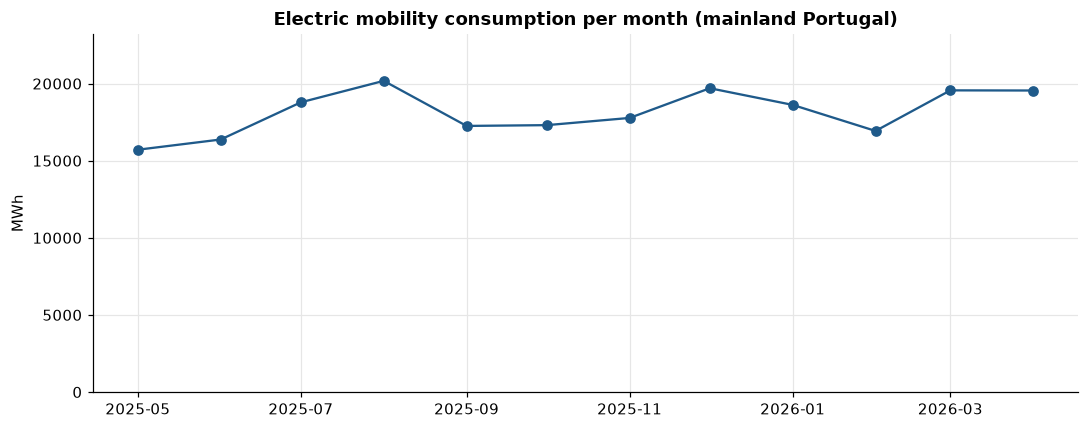

In [13]:
monthly_total = df_mobility.groupby("date")["energy_mwh"].sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly_total.index, monthly_total.values, marker="o", color=MAIN_COLOR)
ax.set_ylabel("MWh")
ax.set_ylim(0, monthly_total.max() * 1.15)
ax.set_title("Electric mobility consumption per month (mainland Portugal)")
plt.tight_layout()
plt.show()

The ranking is led by the largest municipalities, so part of it simply reflects population. Comparing consumption per resident (with population data from INE) would show where adoption is actually ahead, and is a natural next step for the dashboard.

## 6. Market prices vs renewable production

**Merit order effect:** wind and solar have almost no marginal cost, so on days when they produce a lot, fewer expensive gas plants are needed and the market price tends to fall.

REN sometimes publishes prices later than production data, so the two files can end on different days. They are joined on date to keep only the days present in both.

In [14]:
df_merged = df_ren.merge(df_prices, on="date", how="inner")
print(
    f"Merged rows: {len(df_merged)} | {df_merged['date'].min().date()} to {df_merged['date'].max().date()}"
)

CORR_COLUMNS = [
    "pct_renewable",
    "pct_renewable_incl_imports",
    "wind_mwh",
    "solar_mwh",
    "hydro_mwh",
]

Merged rows: 1827 | 2021-10-28 to 2026-10-28


### Correlation with the daily Portuguese price

A correlation over all years mixes very different periods (the 2021-22 energy crisis with very high gas prices, then fast solar growth), and a shared trend alone can create a correlation. The table therefore also shows the correlation **inside each year**. `days` shows how many days each row uses, since the first and last years are partial.

In [15]:
corr_all = (
    df_merged[CORR_COLUMNS + ["price_avg_pt"]]
    .corr()["price_avg_pt"]
    .drop("price_avg_pt")
)

corr_by_year = (
    df_merged.groupby("year")[CORR_COLUMNS + ["price_avg_pt"]]
    .corr()["price_avg_pt"]
    .unstack()
    .drop(columns="price_avg_pt")
)
corr_by_year.loc["all years"] = corr_all
corr_by_year["days"] = df_merged.groupby("year").size()
corr_by_year.loc["all years", "days"] = len(df_merged)
corr_by_year["avg_price_eur_mwh"] = df_merged.groupby("year")["price_avg_pt"].mean()
corr_by_year.loc["all years", "avg_price_eur_mwh"] = df_merged["price_avg_pt"].mean()
corr_by_year["days"] = corr_by_year["days"].astype(int)
corr_by_year.round(3)

,pct_renewable,pct_renewable_incl_imports,wind_mwh,solar_mwh,hydro_mwh,days,avg_price_eur_mwh
year,,,,,,,
2021,-0.410,-0.030,-0.074,-0.072,0.432,65,212.411
2022,-0.280,-0.287,-0.194,0.038,-0.219,365,167.900
2023,-0.723,-0.526,-0.519,0.157,-0.131,365,88.273
2024,-0.755,-0.600,-0.350,-0.009,-0.282,366,63.443
2025,-0.334,-0.253,-0.269,-0.093,0.162,365,66.203
2026,-0.325,-0.585,-0.482,0.467,-0.359,301,82.311
all years,-0.635,-0.515,-0.203,-0.266,-0.363,1827,98.232


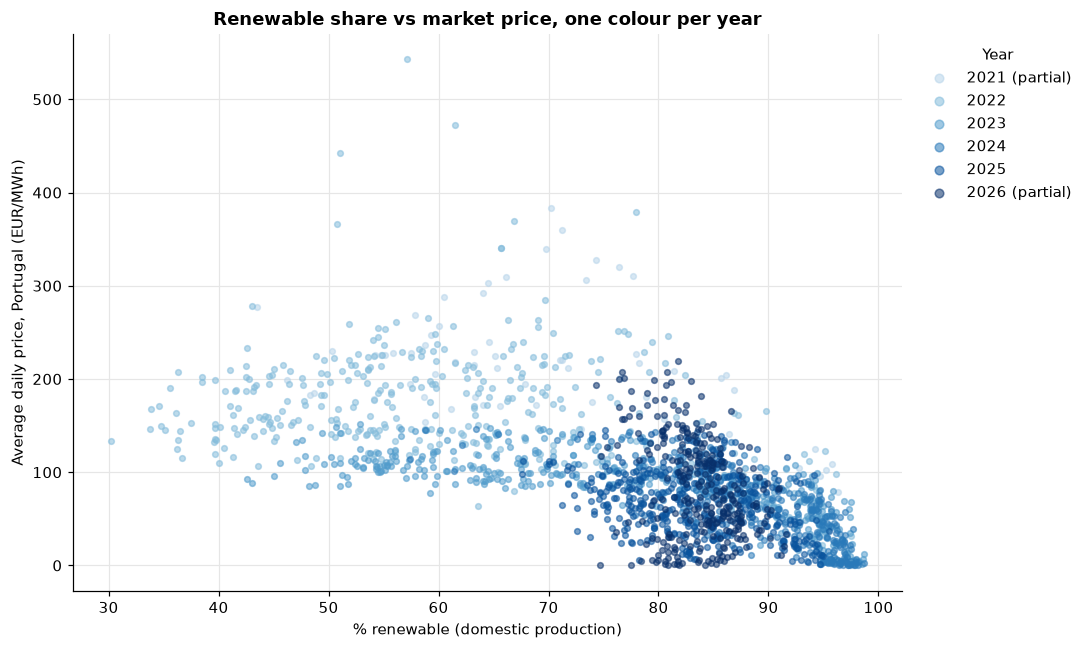

In [16]:
colors = year_colors(sorted(df_merged["year"].unique()))

fig, ax = plt.subplots(figsize=(10, 6))
for year, group in df_merged.groupby("year"):
    ax.scatter(
        group["pct_renewable"],
        group["price_avg_pt"],
        color=colors[year],
        alpha=0.55,
        s=14,
        label=year_label(year),
    )

ax.set_xlabel("% renewable (domestic production)")
ax.set_ylabel("Average daily price, Portugal (EUR/MWh)")
ax.set_title("Renewable share vs market price, one colour per year")
ax.legend(title="Year", markerscale=1.5, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### Market splits between Portugal and Spain

Do price splits happen more on days with a high renewable share? The comparison is made over all years and inside each year, because a year with many splits may simply also be a year with a high renewable share.

In [ ]:
overall = df_merged.groupby("market_split")[SHARE_INPUTS].apply(energy_shares)[
    "pct_renewable"
]
overall_gap = overall[True] - overall[False]

split_by_year = (
    df_merged.groupby(["year", "market_split"])[SHARE_INPUTS]
    .apply(energy_shares)["pct_renewable"]
    .unstack()
    .reindex(columns=[False, True])
)
split_by_year.columns = ["no_split_pct", "split_pct"]
split_by_year["gap_pp"] = split_by_year["split_pct"] - split_by_year["no_split_pct"]
split_by_year["split_days"] = df_merged.groupby("year")["market_split"].sum()
split_by_year["split_days_pct"] = df_merged.groupby("year")["market_split"].mean() * 100
split_by_year.index = [year_label(y) for y in split_by_year.index]

gaps = split_by_year["gap_pp"].dropna()
print(
    f"All years: {overall[True]:.1f}% renewable on split days vs {overall[False]:.1f}% on other days "
    f"({overall_gap:+.1f} pp)"
)
print(
    f"Inside each year the gap ranges from {gaps.min():+.1f} to {gaps.max():+.1f} pp "
    f"and is positive in {int((gaps > 0).sum())} of {len(gaps)} years"
)
split_by_year.round(1)

All years: 81.2% renewable on split days vs 78.3% on other days (+2.9 pp)
Inside each year the gap ranges from -11.0 to +2.5 pp and is positive in 2 of 6 years


,no_split_pct,split_pct,gap_pp,split_days,split_days_pct
2021 (partial),69.2,58.2,-11.0,3,4.6
2022,62.1,64.6,2.5,34,9.3
2023,76.9,79.3,2.4,60,16.4
2024,88.8,88.4,-0.3,57,15.6
2025,83.9,83.5,-0.4,79,21.6
2026 (partial),84.5,82.1,-2.4,77,25.6


If the gap only appears when all years are pooled, and changes sign inside the years, it reflects which years had many splits more than any link between renewables and splits on a given day. Years with only a handful of split days, such as a short partial year, are too small to read on their own.

## Key findings

*From the run of 28 October 2026, with data from 27 October 2021 to 27 October 2026. The exact values move a little every time the window rolls forward.*

1. **The renewable share has grown a lot, but not in a straight line.** Domestic production was 62.3% renewable in 2022, 77.2% in 2023 and 88.7% in 2024, before falling back to 83.8% in 2025. 2022 was the weak year: hydro averaged about 23,800 MWh a day, less than half of 2024, and natural gas filled the gap.
2. **Solar is the steady growth story.** Average solar output went from about 6,900 MWh a day in 2022 to 16,700 in 2025, around 2.4 times more.
3. **Spring is the renewable peak and summer the low point.** Across 2022-2025, April reaches 85.3% and July only 69.6%. Hydro and wind drop in summer, and solar does not yet make up the difference.
4. **Hydro has become steadier from day to day, wind has not.** Inside each year, the coefficient of variation of hydro fell from 0.81 in 2022 to 0.47 in 2025, while wind stayed between 0.63 and 0.67.
5. **The 2025 dip came from more gas, not from less renewable power.** From April to June, renewable output was 2,913 MWh a day higher in 2025 than in 2024, yet the share fell from 95.2% to 85.4%. The change starts on 29 April 2025, the day after the blackout: imports dropped to almost zero for nine days and gas output jumped. Imports had mostly recovered by June, but gas stayed well above 2024 levels from May to November (21,000 to 25,000 MWh a day, against 4,000 to 19,000 a year earlier). December 2025 was the first month since the blackout with less gas than a year before.
6. **Electric mobility is concentrated around Lisbon and Porto.** Over the 12 months available, Lisbon district accounts for 37.1% of mainland consumption and Porto district for 15.9%. The top 10 municipalities add up to 41.7%.
7. **More renewables go with lower prices inside every year.** The correlation between the renewable share and the daily Portuguese price is negative in all six years, between -0.28 and -0.76. Solar output on its own does not show the same pattern, which suggests that the link runs through the overall mix rather than through a single source.
8. **Prices rose sharply in the second half of 2026.** The Portuguese monthly average went from about 70 EUR/MWh in June to 107 in July, 144 in September and 161 in October so far, in line with the figures published by OMIE.
9. **Market splits are becoming more common, but they are not tied to greener days.** Days with different Portuguese and Spanish prices went from 9.3% of the year in 2022 to 21.6% in 2025 (25.3% so far in 2026). Inside each full year, split days are at most 2.5 points more renewable than other days, and in 2024 and 2025 slightly less.

## Notes

- Correlation is not causation. The by-year tables are a first control for shared trends, not proof of the merit order effect.
- Both definitions of the renewable share are kept throughout. Official figures use the import balance, so they usually fall between the two.
- Results move as the extraction window rolls forward; every printed number refers to the latest run.